# Massachusetts State-Level DSCI Prediction

In [89]:
import requests

url = (
    "https://usdmdataservices.unl.edu/api/StateStatistics/GetDSCI"
    "?aoi=25"
    "&startdate=1/4/2000"
    "&enddate=4/9/2026"
    "&statisticsType=1"
)

response = requests.get(url, headers={"Accept": "text/csv"}, timeout=60)
response.raise_for_status()

with open("massachusetts_dsci.csv", "wb") as f:
    f.write(response.content)

print("Saved as massachusetts_dsci.csv")

Saved as massachusetts_dsci.csv


In [90]:
import pandas as pd

df = pd.read_csv("massachusetts_dsci.csv")

# basic check
print(df.head())
print("\nColumns:", df.columns)
print("\nShape:", df.shape)

            Name   MapDate  DSCI
0  Massachusetts  20000104     0
1  Massachusetts  20000111     0
2  Massachusetts  20000118     0
3  Massachusetts  20000125     0
4  Massachusetts  20000201     0

Columns: Index(['Name', 'MapDate', 'DSCI'], dtype='object')

Shape: (1371, 3)


In [91]:
# Convert MapDate to datetime
df['MapDate'] = pd.to_datetime(df['MapDate'], format='%Y%m%d')

# Sort by date (important for time series)
df = df.sort_values('MapDate').reset_index(drop=True)

# Check again
print(df.head())
print(df.tail())

            Name    MapDate  DSCI
0  Massachusetts 2000-01-04     0
1  Massachusetts 2000-01-11     0
2  Massachusetts 2000-01-18     0
3  Massachusetts 2000-01-25     0
4  Massachusetts 2000-02-01     0
               Name    MapDate  DSCI
1366  Massachusetts 2026-03-10   164
1367  Massachusetts 2026-03-17   146
1368  Massachusetts 2026-03-24   131
1369  Massachusetts 2026-03-31   122
1370  Massachusetts 2026-04-07   111


In [92]:
# Training data: 2011–2020
train_df = df[(df['MapDate'] >= '2011-01-01') & (df['MapDate'] <= '2020-12-31')].reset_index(drop=True)

# Testing data: 2021
test_df = df[(df['MapDate'] >= '2021-01-01') & (df['MapDate'] <= '2021-12-31')].reset_index(drop=True)

print("Train size:", len(train_df))
print("Test size:", len(test_df))

Train size: 522
Test size: 52


In [93]:
def classify(dsci):
    if dsci < 24:
        return 0   # near normal
    elif dsci < 116:
        return 1   # mild/moderate drought
    else:
        return 2   # high drought

train_df['State'] = train_df['DSCI'].apply(classify)
test_df['State'] = test_df['DSCI'].apply(classify)

print("Train sample:")
print(train_df[['MapDate', 'DSCI', 'State']].head())

print("\nTest sample:")
print(test_df[['MapDate', 'DSCI', 'State']].head())

Train sample:
     MapDate  DSCI  State
0 2011-01-04     0      0
1 2011-01-11     0      0
2 2011-01-18     0      0
3 2011-01-25     0      0
4 2011-02-01     0      0

Test sample:
     MapDate  DSCI  State
0 2021-01-05     0      0
1 2021-01-12     0      0
2 2021-01-19     0      0
3 2021-01-26     0      0
4 2021-02-02     0      0


In [94]:
import numpy as np
import pandas as pd

# 3 states: 0, 1, 2
N = np.zeros((3, 3), dtype=int)

for i in range(len(train_df) - 1):
    current_state = train_df.loc[i, 'State']
    next_state = train_df.loc[i + 1, 'State']
    N[current_state, next_state] += 1

N_df = pd.DataFrame(
    N,
    index=['Normal', 'Moderate', 'Severe'],
    columns=['Normal', 'Moderate', 'Severe']
)

print("Transition count matrix N_ij:")
print(N_df)

Transition count matrix N_ij:
          Normal  Moderate  Severe
Normal       297        12       0
Moderate      11        83      12
Severe         1        11      94


In [95]:
alpha = 0.5
num_states = 3

# Apply formula: P_ij = (N_ij + alpha) / sum_j(N_ij + alpha)
P = (N + alpha) / (N.sum(axis=1, keepdims=True) + alpha * num_states)

# Convert to DataFrame for clarity
P_df = pd.DataFrame(
    P,
    index=['Normal', 'Moderate', 'Severe'],
    columns=['Normal', 'Moderate', 'Severe']
)

print("Smoothed Transition Probability Matrix P_ij:")
print(P_df)

print("\nRow sums (should be 1):")
print(P_df.sum(axis=1))

Smoothed Transition Probability Matrix P_ij:
            Normal  Moderate    Severe
Normal    0.958132  0.040258  0.001610
Moderate  0.106977  0.776744  0.116279
Severe    0.013953  0.106977  0.879070

Row sums (should be 1):
Normal      1.0
Moderate    1.0
Severe      1.0
dtype: float64


In [96]:
y_true = []
y_pred = []
y_prob = []

for i in range(len(test_df) - 1):
    current_state = test_df.loc[i, 'State']
    true_next_state = test_df.loc[i + 1, 'State']

    # Get probability distribution from trained matrix
    prob_next = P[current_state]

    # Predicted state = max probability
    pred_next_state = np.argmax(prob_next)

    y_true.append(true_next_state)
    y_pred.append(pred_next_state)
    y_prob.append(prob_next)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("First 10 true states:     ", y_true[:10])
print("First 10 predicted states:", y_pred[:10])
print("Total predictions:", len(y_true))

First 10 true states:      [0 0 0 0 0 0 0 0 0 1]
First 10 predicted states: [0 0 0 0 0 0 0 0 0 0]
Total predictions: 51


In [97]:
from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(y_true, y_pred)
f1_macro = f1_score(y_true, y_pred, average='macro')

print("Accuracy:", accuracy)
print("F1-macro:", f1_macro)

Accuracy: 0.9607843137254902
F1-macro: 0.9258720930232558


In [98]:
from sklearn.metrics import log_loss

# Log Loss (cross-entropy)
logloss = log_loss(y_true, y_prob, labels=[0,1,2])

# Brier Score (multiclass)
y_true_onehot = np.eye(3)[y_true]
brier_score = np.mean(np.sum((y_prob - y_true_onehot) ** 2, axis=1))

print("Log Loss:", logloss)
print("Brier Score:", brier_score)

Log Loss: 0.17671441152019213
Brier Score: 0.07684165064751795


# Suffolk County DSCI Prediction

In [99]:
import requests

url = (
    "https://usdmdataservices.unl.edu/api/CountyStatistics/GetDSCI"
    "?aoi=25025"
    "&startdate=1/4/2000"
    "&enddate=4/9/2026"
    "&statisticsType=1"
)

response = requests.get(url, headers={"Accept": "text/csv"}, timeout=60)
response.raise_for_status()

with open("suffolk_dsci.csv", "wb") as f:
    f.write(response.content)

print("Saved as suffolk_dsci.csv")

Saved as suffolk_dsci.csv


In [100]:
import pandas as pd

df_suffolk = pd.read_csv("suffolk_dsci.csv")

print(df_suffolk.head())
print("\nColumns:", df_suffolk.columns)
print("\nShape:", df_suffolk.shape)

  State          County   FIPS   MapDate  DSCI
0    MA  Suffolk County  25025  20000104     0
1    MA  Suffolk County  25025  20000111     0
2    MA  Suffolk County  25025  20000118     0
3    MA  Suffolk County  25025  20000125     0
4    MA  Suffolk County  25025  20000201     0

Columns: Index(['State', 'County', 'FIPS', 'MapDate', 'DSCI'], dtype='object')

Shape: (1371, 5)


In [101]:
# Convert date
df_suffolk['MapDate'] = pd.to_datetime(df_suffolk['MapDate'], format='%Y%m%d')

# Sort
df_suffolk = df_suffolk.sort_values('MapDate').reset_index(drop=True)

print(df_suffolk.head())
print(df_suffolk.tail())

  State          County   FIPS    MapDate  DSCI
0    MA  Suffolk County  25025 2000-01-04     0
1    MA  Suffolk County  25025 2000-01-11     0
2    MA  Suffolk County  25025 2000-01-18     0
3    MA  Suffolk County  25025 2000-01-25     0
4    MA  Suffolk County  25025 2000-02-01     0
     State          County   FIPS    MapDate  DSCI
1366    MA  Suffolk County  25025 2026-03-10   200
1367    MA  Suffolk County  25025 2026-03-17   200
1368    MA  Suffolk County  25025 2026-03-24   200
1369    MA  Suffolk County  25025 2026-03-31   198
1370    MA  Suffolk County  25025 2026-04-07   198


In [102]:
# Training data: 2011–2020
train_suffolk = df_suffolk[(df_suffolk['MapDate'] >= '2011-01-01') &
                          (df_suffolk['MapDate'] <= '2020-12-31')].reset_index(drop=True)

# Testing data: 2021
test_suffolk = df_suffolk[(df_suffolk['MapDate'] >= '2021-01-01') &
                         (df_suffolk['MapDate'] <= '2021-12-31')].reset_index(drop=True)

print("Train size:", len(train_suffolk))
print("Test size:", len(test_suffolk))

print("\nTrain sample:")
print(train_suffolk[['MapDate','DSCI']].head())

print("\nTest sample:")
print(test_suffolk[['MapDate','DSCI']].head())

Train size: 522
Test size: 52

Train sample:
     MapDate  DSCI
0 2011-01-04     0
1 2011-01-11     0
2 2011-01-18     0
3 2011-01-25     0
4 2011-02-01     0

Test sample:
     MapDate  DSCI
0 2021-01-05     0
1 2021-01-12     0
2 2021-01-19     0
3 2021-01-26     0
4 2021-02-02     0


In [103]:
def classify(dsci):
    if dsci < 24:
        return 0   # Normal
    elif dsci < 116:
        return 1   # Moderate
    else:
        return 2   # Severe

train_suffolk['State'] = train_suffolk['DSCI'].apply(classify)
test_suffolk['State'] = test_suffolk['DSCI'].apply(classify)

print("Train sample:")
print(train_suffolk[['MapDate', 'DSCI', 'State']].head())

print("\nTest sample:")
print(test_suffolk[['MapDate', 'DSCI', 'State']].head())

Train sample:
     MapDate  DSCI  State
0 2011-01-04     0      0
1 2011-01-11     0      0
2 2011-01-18     0      0
3 2011-01-25     0      0
4 2011-02-01     0      0

Test sample:
     MapDate  DSCI  State
0 2021-01-05     0      0
1 2021-01-12     0      0
2 2021-01-19     0      0
3 2021-01-26     0      0
4 2021-02-02     0      0


In [104]:
import numpy as np
import pandas as pd

# Initialize matrix
N_suffolk = np.zeros((3,3), dtype=int)

for i in range(len(train_suffolk) - 1):
    curr = train_suffolk.loc[i, 'State']
    next_ = train_suffolk.loc[i + 1, 'State']
    N_suffolk[curr, next_] += 1

# Display nicely
N_suffolk_df = pd.DataFrame(
    N_suffolk,
    index=['Normal', 'Moderate', 'Severe'],
    columns=['Normal', 'Moderate', 'Severe']
)

print("Transition Count Matrix (Suffolk):")
print(N_suffolk_df)

Transition Count Matrix (Suffolk):
          Normal  Moderate  Severe
Normal       313        13       0
Moderate      12        87       8
Severe         1         7      80


In [105]:
alpha = 0.5
num_states = 3

# Apply smoothing formula
P_suffolk = (N_suffolk + alpha) / (N_suffolk.sum(axis=1, keepdims=True) + alpha * num_states)

# Display nicely
P_suffolk_df = pd.DataFrame(
    P_suffolk,
    index=['Normal', 'Moderate', 'Severe'],
    columns=['Normal', 'Moderate', 'Severe']
)

print("Smoothed Transition Matrix (Suffolk):")
print(P_suffolk_df)

print("\nRow sums:")
print(P_suffolk_df.sum(axis=1))


Smoothed Transition Matrix (Suffolk):
            Normal  Moderate    Severe
Normal    0.957252  0.041221  0.001527
Moderate  0.115207  0.806452  0.078341
Severe    0.016760  0.083799  0.899441

Row sums:
Normal      1.0
Moderate    1.0
Severe      1.0
dtype: float64


In [106]:
y_true_s = []
y_pred_s = []
y_prob_s = []

for i in range(len(test_suffolk) - 1):
    current_state = test_suffolk.loc[i, 'State']
    true_next_state = test_suffolk.loc[i + 1, 'State']

    prob_next = P_suffolk[current_state]
    pred_next_state = np.argmax(prob_next)

    y_true_s.append(true_next_state)
    y_pred_s.append(pred_next_state)
    y_prob_s.append(prob_next)

y_true_s = np.array(y_true_s)
y_pred_s = np.array(y_pred_s)
y_prob_s = np.array(y_prob_s)

print("First 10 true states:     ", y_true_s[:10])
print("First 10 predicted states:", y_pred_s[:10])
print("Total predictions:", len(y_true_s))

First 10 true states:      [0 0 0 0 0 0 0 0 0 0]
First 10 predicted states: [0 0 0 0 0 0 0 0 0 0]
Total predictions: 51


In [107]:
from sklearn.metrics import accuracy_score, f1_score

accuracy_s = accuracy_score(y_true_s, y_pred_s)
f1_macro_s = f1_score(y_true_s, y_pred_s, average='macro')

print("Accuracy:", accuracy_s)
print("F1-macro:", f1_macro_s)

Accuracy: 0.9607843137254902
F1-macro: 0.8891304347826088


In [108]:
from sklearn.metrics import log_loss


logloss_s = log_loss(y_true_s, y_prob_s, labels=[0,1,2])

y_true_onehot_s = np.eye(3)[y_true_s]

brier_score_s = np.mean(
    np.sum((y_prob_s - y_true_onehot_s) ** 2, axis=1)
)

print("Log Loss:", logloss_s)
print("Brier Score:", brier_score_s)

Log Loss: 0.16031875866423273
Brier Score: 0.07178893277882341


In [109]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "F1-macro", "Log Loss", "Brier Score"],
    "Massachusetts": [
        accuracy,
        f1_macro,
        logloss,
        brier_score
    ],
    "Suffolk County": [
        accuracy_s,
        f1_macro_s,
        logloss_s,
        brier_score_s
    ]
})

print(comparison)

        Metric  Massachusetts  Suffolk County
0     Accuracy       0.960784        0.960784
1     F1-macro       0.925872        0.889130
2     Log Loss       0.176714        0.160319
3  Brier Score       0.076842        0.071789


In [110]:
from sklearn.metrics import accuracy_score, f1_score, log_loss

def compare_models(train, test, P, name):
    cur = test['State'].values[:-1]
    nxt = test['State'].values[1:]
    onehot = np.eye(3)[nxt]

    # Persistence
    pers_pred = cur

    # Climatology (training-year base rates)
    freq = np.bincount(train['State'], minlength=3) / len(train)
    clim_prob = np.tile(freq, (len(nxt), 1))
    clim_pred = clim_prob.argmax(axis=1)

    # Markov chain
    mk_prob = P[cur]
    mk_pred = mk_prob.argmax(axis=1)

    rows = []
    for label, pred, prob in [
        ("Persistence (no change)", pers_pred, None),
        ("Climatology (base rates)", clim_pred, clim_prob),
        ("Markov chain", mk_pred, mk_prob),
    ]:
        row = {
            "Model": label,
            "Accuracy": accuracy_score(nxt, pred),
            "F1-macro": f1_score(nxt, pred, average="macro", zero_division=0),
            "Log loss": log_loss(nxt, prob, labels=[0, 1, 2]) if prob is not None else np.nan,
            "Brier": np.mean(np.sum((prob - onehot) ** 2, axis=1)) if prob is not None else np.nan,
        }
        rows.append(row)

    print(f"===== {name} =====")
    print("Week-to-week state changes in the test year:", int((cur != nxt).sum()), "of", len(nxt))
    print("Markov point predictions identical to persistence?", bool(np.array_equal(mk_pred, pers_pred)))
    result = pd.DataFrame(rows).round(3)
    print(result.to_string(index=False))
    return result

ma_results = compare_models(train_df, test_df, P, "Massachusetts")
print()
suffolk_results = compare_models(train_suffolk, test_suffolk, P_suffolk, "Suffolk County")


===== Massachusetts =====
Week-to-week state changes in the test year: 2 of 51
Markov point predictions identical to persistence? True
                   Model  Accuracy  F1-macro  Log loss  Brier
 Persistence (no change)     0.961     0.926       NaN    NaN
Climatology (base rates)     0.843     0.457     0.689  0.370
            Markov chain     0.961     0.926     0.177  0.077

===== Suffolk County =====
Week-to-week state changes in the test year: 2 of 51
Markov point predictions identical to persistence? True
                   Model  Accuracy  F1-macro  Log loss  Brier
 Persistence (no change)     0.961     0.889       NaN    NaN
Climatology (base rates)     0.902     0.474     0.577  0.293
            Markov chain     0.961     0.889     0.160  0.072


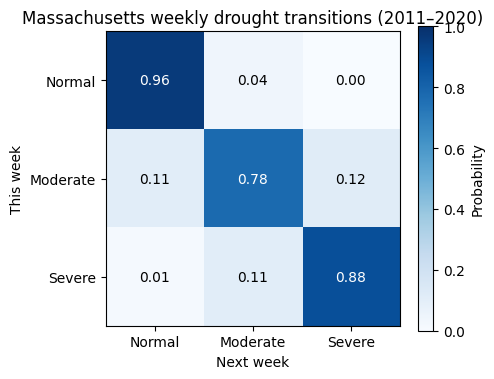

In [111]:
import matplotlib.pyplot as plt
import os

os.makedirs("images", exist_ok=True)
labels = ["Normal", "Moderate", "Severe"]

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(P, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(labels)
ax.set_yticks(range(3)); ax.set_yticklabels(labels)
ax.set_xlabel("Next week"); ax.set_ylabel("This week")
ax.set_title("Massachusetts weekly drought transitions (2011–2020)")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{P[i, j]:.2f}", ha="center", va="center",
                color="white" if P[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, label="Probability")
plt.tight_layout()
plt.savefig("images/transition_matrix.png", dpi=150)
plt.show()

# In Colab, download it:
# from google.colab import files; files.download("images/transition_matrix.png")


   # v2: Weather Features and Machine Learning Models

In [112]:
# Step 1: Weekly Weather Data (NOAA, Boston Logan Airport)
import pandas as pd
import requests, io, os, time

WEATHER_FILE = "boston_weather_daily.csv"
url = (
    "https://www.ncei.noaa.gov/access/services/data/v1"
    "?dataset=daily-summaries&stations=USW00014739"
    "&startDate=2000-01-01&endDate=2026-04-07"
    "&dataTypes=PRCP,TMAX,TMIN&units=standard&format=csv"
)

if os.path.exists(WEATHER_FILE):
    weather = pd.read_csv(WEATHER_FILE, parse_dates=["DATE"])
    print("Loaded saved copy")
else:
    for attempt in range(1, 6):
        r = requests.get(url, timeout=120)
        if r.status_code == 200:
            break
        print(f"NOAA busy (error {r.status_code}), retrying in 30 seconds... ({attempt}/5)")
        time.sleep(30)
    r.raise_for_status()
    weather = pd.read_csv(io.StringIO(r.text), parse_dates=["DATE"])
    weather.to_csv(WEATHER_FILE, index=False)
    print("Downloaded from NOAA")

print("Daily rows:", len(weather))

weather = weather.set_index("DATE").sort_index()
weekly = pd.DataFrame({
    "precip_in": weather["PRCP"].resample("W-TUE").sum(min_count=1),
    "tmax_f":    weather["TMAX"].resample("W-TUE").mean(),
    "tmin_f":    weather["TMIN"].resample("W-TUE").mean(),
}).reset_index().rename(columns={"DATE": "MapDate"})

ma = df.merge(weekly, on="MapDate", how="left")
print("Weeks missing weather:", ma["precip_in"].isna().sum())

Loaded saved copy
Daily rows: 9594
Weeks missing weather: 0


In [113]:
# Step 2: Features
import numpy as np

def build_features(dsci_df, weekly_weather):
    d = (dsci_df[["MapDate", "DSCI"]]
         .merge(weekly_weather, on="MapDate", how="left")
         .sort_values("MapDate").reset_index(drop=True))
    d["State"] = d["DSCI"].apply(classify)

    # Drought history: how fast DSCI is changing
    d["dsci_change_1w"] = d["DSCI"].diff(1)
    d["dsci_change_4w"] = d["DSCI"].diff(4)

    # Rainfall over the last 1, 4 and 12 weeks
    for w in (1, 4, 12):
        d[f"precip_{w}w"] = d["precip_in"].rolling(w).sum()

    # Rainfall vs. normal: compared with the 2000-2010 average for the same week of the year
    # (2000-2010 is never used for training or testing, so this doesn't leak test data)
    d["week_of_year"] = d["MapDate"].dt.isocalendar().week.astype(int).clip(upper=52)
    normal_4w = d[d["MapDate"] < "2011-01-01"].groupby("week_of_year")["precip_4w"].mean()
    d["precip_4w_anomaly"] = d["precip_4w"] - d["week_of_year"].map(normal_4w)

    # Temperature (average daily high over the last 4 weeks)
    d["tmax_4w"] = d["tmax_f"].rolling(4).mean()

    # Season, encoded so that week 52 and week 1 are close together
    d["season_sin"] = np.sin(2 * np.pi * d["week_of_year"] / 52)
    d["season_cos"] = np.cos(2 * np.pi * d["week_of_year"] / 52)

    # Target: next week's drought state
    d["next_state"] = d["State"].shift(-1)
    d = d.dropna().reset_index(drop=True)
    d["next_state"] = d["next_state"].astype(int)
    return d

FEATURES = ["State", "DSCI", "dsci_change_1w", "dsci_change_4w",
            "precip_1w", "precip_4w", "precip_12w", "precip_4w_anomaly",
            "tmax_4w", "season_sin", "season_cos"]

ma_feat = build_features(df, weekly)
suffolk_feat = build_features(df_suffolk, weekly)

for name, d in [("Massachusetts", ma_feat), ("Suffolk County", suffolk_feat)]:
    d_ = d[d["MapDate"] >= "2011-01-01"]
    changes = (d_["State"] != d_["next_state"]).groupby(d_["MapDate"].dt.year).sum()
    print(f"{name}")
    print("Rows:", len(d), "| from", d["MapDate"].min().date(), "to", d["MapDate"].max().date())
    print("Next-state counts (2011+):", d_["next_state"].value_counts().sort_index().to_dict())
    print("State changes per year (2011+):", changes.to_dict())
    print()

print(ma_feat[["MapDate", "State", "DSCI", "precip_4w", "precip_4w_anomaly", "tmax_4w", "next_state"]].tail())

Massachusetts
Rows: 1359 | from 2000-03-21 to 2026-03-31
Next-state counts (2011+): {0: 459, 1: 165, 2: 172}
State changes per year (2011+): {2011: 0, 2012: 6, 2013: 8, 2014: 6, 2015: 7, 2016: 3, 2017: 5, 2018: 4, 2019: 2, 2020: 6, 2021: 2, 2022: 3, 2023: 7, 2024: 6, 2025: 8, 2026: 1}

Suffolk County
Rows: 1359 | from 2000-03-21 to 2026-03-31
Next-state counts (2011+): {0: 488, 1: 168, 2: 140}
State changes per year (2011+): {2011: 0, 2012: 6, 2013: 4, 2014: 6, 2015: 7, 2016: 3, 2017: 5, 2018: 2, 2019: 2, 2020: 6, 2021: 2, 2022: 3, 2023: 3, 2024: 5, 2025: 4, 2026: 1}

        MapDate  State  DSCI  precip_4w  precip_4w_anomaly    tmax_4w  \
1354 2026-03-03      2   164       1.59          -1.421818  35.107143   
1355 2026-03-10      2   164       2.11          -1.514545  41.321429   
1356 2026-03-17      2   146       3.28          -0.297273  45.464286   
1357 2026-03-24      2   131       3.36          -0.705455  47.785714   
1358 2026-03-31      2   122       3.13          -1.229091  

In [114]:
# Step 3: Models + rolling yearly evaluation
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, log_loss
from xgboost import XGBClassifier

def markov_proba(train, cur_states, alpha=0.5):
    N = np.zeros((3, 3))
    for a, b in zip(train["State"], train["next_state"]):
        N[a, b] += 1
    P_ = (N + alpha) / (N.sum(axis=1, keepdims=True) + 3 * alpha)
    return P_[cur_states]

def ml_proba(make_model, Xtr, ytr, Xte):
    # handles training years where one drought state never appeared
    classes = np.unique(ytr)
    enc = {c: i for i, c in enumerate(classes)}
    m = make_model()
    m.fit(Xtr, np.array([enc[c] for c in ytr]))
    out = np.full((len(Xte), 3), 1e-6)
    out[:, classes] = m.predict_proba(Xte)
    return out / out.sum(axis=1, keepdims=True)

MODELS = {
    "Logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "XGBoost": lambda: XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                     subsample=0.8, colsample_bytree=0.8, eval_metric="mlogloss"),
}

def rolling_eval(d, years=range(2012, 2026)):
    rec = {k: [] for k in ["year", "cur", "y"]}
    probs = {name: [] for name in ["Climatology", "Markov chain", *MODELS]}
    for Y in years:
        train = d[d["MapDate"].dt.year < Y]
        test = d[d["MapDate"].dt.year == Y]
        cur, y = test["State"].values, test["next_state"].values
        rec["year"] += [Y] * len(test); rec["cur"] += list(cur); rec["y"] += list(y)

        freq = (np.bincount(train["next_state"], minlength=3) + 0.5) / (len(train) + 1.5)
        probs["Climatology"].append(np.tile(freq, (len(test), 1)))
        probs["Markov chain"].append(markov_proba(train, cur))
        for name, make in MODELS.items():
            probs[name].append(ml_proba(make, train[FEATURES], train["next_state"].values, test[FEATURES]))

    cur, y = np.array(rec["cur"]), np.array(rec["y"])
    probs = {k: np.vstack(v) for k, v in probs.items()}
    return np.array(rec["year"]), cur, y, probs

def score(cur, y, pred, prob):
    changed = cur != y
    return {
        "Accuracy": accuracy_score(y, pred),
        "F1-macro": f1_score(y, pred, average="macro", zero_division=0),
        "Log loss": log_loss(y, prob, labels=[0, 1, 2]) if prob is not None else np.nan,
        "Brier": np.mean(np.sum((prob - np.eye(3)[y]) ** 2, axis=1)) if prob is not None else np.nan,
        "Changes caught": f"{int((pred[changed] == y[changed]).sum())}/{int(changed.sum())}",
        "False alarms": int(((pred != cur) & ~changed).sum()),
    }

results = {}
for name, d in [("Massachusetts", ma_feat), ("Suffolk County", suffolk_feat)]:
    years, cur, y, probs = rolling_eval(d)
    rows = [{"Model": "Persistence (no change)", **score(cur, y, cur, None)}]
    for m, p in probs.items():
        rows.append({"Model": m, **score(cur, y, p.argmax(axis=1), p)})
    table = pd.DataFrame(rows).round(3)
    results[name] = {"years": years, "cur": cur, "y": y, "probs": probs, "table": table}
    print(f"{name}: {len(y)} weekly forecasts, 2012–2025")
    print(table.to_string(index=False))
    print()

Massachusetts: 731 weekly forecasts, 2012–2025
                  Model  Accuracy  F1-macro  Log loss  Brier Changes caught  False alarms
Persistence (no change)     0.900     0.877       NaN    NaN           0/73             0
            Climatology     0.557     0.238     1.086  0.643          21/73           272
           Markov chain     0.900     0.877     0.351  0.179           0/73             0
    Logistic regression     0.873     0.840     0.313  0.183           8/73            28
                XGBoost     0.860     0.826     0.346  0.198          13/73            42

Suffolk County: 731 weekly forecasts, 2012–2025
                  Model  Accuracy  F1-macro  Log loss  Brier Changes caught  False alarms
Persistence (no change)     0.921     0.900       NaN    NaN           0/58             0
            Climatology     0.596     0.249     1.038  0.610          18/58           255
           Markov chain     0.921     0.900     0.302  0.147           0/58             0
    

Logistic regression coefficients (standardized features):
                   Normal  Moderate  Severe
State               -1.42      0.14    1.28
DSCI                -2.73      0.14    2.58
dsci_change_1w      -0.13      0.15   -0.02
dsci_change_4w       0.08     -0.29    0.21
precip_1w            0.15      0.16   -0.31
precip_4w            0.32     -0.25   -0.07
precip_12w           0.47     -0.15   -0.32
precip_4w_anomaly    0.24     -0.10   -0.14
tmax_4w             -0.46      0.42    0.04
season_sin          -0.25      0.24    0.00
season_cos           0.03      0.16   -0.19


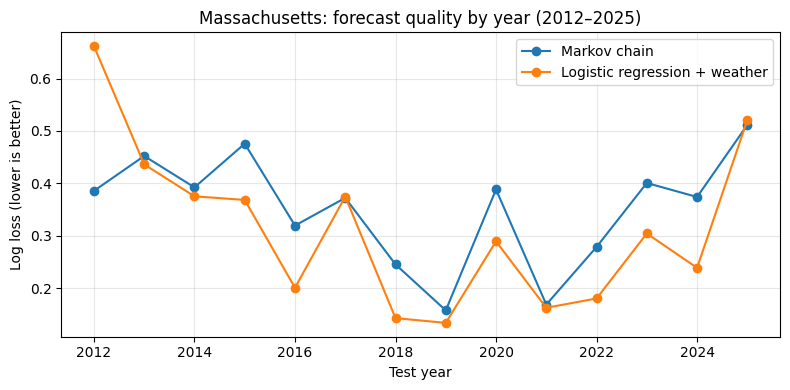

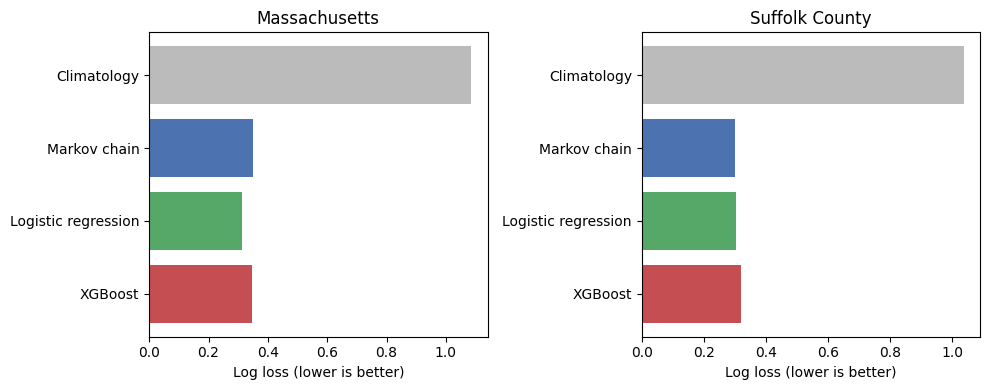

In [115]:
# Step 4: Feature effects + charts
import matplotlib.pyplot as plt
import os
os.makedirs("images", exist_ok=True)

# 1) Which features matter? (logistic regression trained on all Massachusetts weeks up to 2025)
d = ma_feat[ma_feat["MapDate"].dt.year <= 2025]
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
lr.fit(d[FEATURES], d["next_state"])
coefs = pd.DataFrame(lr[-1].coef_, index=["Normal", "Moderate", "Severe"], columns=FEATURES).T
print("Logistic regression coefficients (standardized features):")
print(coefs.round(2))

# 2) Log loss per test year: Markov chain vs logistic regression (Massachusetts)
r = results["Massachusetts"]
yrs = sorted(set(r["years"]))
def yearly_logloss(p):
    return [log_loss(r["y"][r["years"] == Y], p[r["years"] == Y], labels=[0, 1, 2]) for Y in yrs]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(yrs, yearly_logloss(r["probs"]["Markov chain"]), marker="o", label="Markov chain")
ax.plot(yrs, yearly_logloss(r["probs"]["Logistic regression"]), marker="o", label="Logistic regression + weather")
ax.set_xlabel("Test year"); ax.set_ylabel("Log loss (lower is better)")
ax.set_title("Massachusetts: forecast quality by year (2012–2025)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("images/yearly_logloss.png", dpi=150); plt.show()

# 3) Results summary chart
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["Massachusetts", "Suffolk County"]):
    t = results[name]["table"].dropna(subset=["Log loss"])
    ax.barh(t["Model"], t["Log loss"], color=["#bbb", "#4c72b0", "#55a868", "#c44e52"])
    ax.set_title(name); ax.set_xlabel("Log loss (lower is better)"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig("images/model_comparison.png", dpi=150); plt.show()